
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Simulación del movimiento browniano

Realizar un código para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma $f = -kx$.

## Parámetros de la simulación

Se trabaja en el **régimen sobreamortiguado** (sin inercia), en unidades arbitrarias.

| Parámetro | Símbolo | Valor | Descripción |
|---|---|---|---|
| `gamma` | $\gamma$ | 1.0 | coeficiente de fricción |
| `kB_T` | $k_BT$ | 1.0 | energía térmica |
| `k` | $k$ | 2.0 | constante del resorte |
| `D` | $D = \dfrac{k_BT}{\gamma}$ | 1.0 | coeficiente de difusión |
| `n_part` | — | 500 | número de partículas simuladas |
| `n_pasos` | — | 2000 | número de pasos de tiempo |
| `dt` | $\Delta t$ | 0.005 | tamaño de cada paso |

El tiempo total simulado es $t_{\text{final}} = 2000 \times 0.005 = 10$.

El vector `t` guarda los instantes $t_n = n\,\Delta t$, para $n = 0, 1, \dots, 2000$ (2001 valores, porque incluye $t = 0$).

## Valores esperados

- Ruido en cada paso: $\sqrt{2D\,\Delta t} = \sqrt{0.01} = 0.1$
- Varianza al final **sin fuerza**: $\operatorname{Var}(x) = 2Dt = 20$
- Varianza al final **con resorte**: $\operatorname{Var}(x) = \dfrac{k_BT}{k} = 0.5$

In [2]:
rng = np.random.default_rng(42)   # generador aleatorio con semilla fija

gamma = 1.0      # fricción
kB_T  = 1.0      # temperatura (kB·T)
k     = 2.0      # constante del resorte
D     = kB_T / gamma  # coeficiente de difusión: ¿cuál es la fórmula con kB_T y gamma?

n_part  = 500    # cuántas partículas simulamos
n_pasos = 2000
dt      = 0.005
t = np.arange(n_pasos + 1) * dt   # vector de tiempos: 0, 0.005, 0.010, ...

In [3]:
# posiciones de las partículas en el tiempo. Es de tamaño 500x2001
x_libre = np.zeros((n_part, n_pasos + 1))    
x_resorte = np.zeros((n_part, n_pasos + 1))  

# Tomar la posición de todas las partículas en el tiempo t y calcular donde quedan en el tiempo t+dt
for j in range(n_pasos):
    Z = rng.normal(0, 1, n_part)  # vector de números aleatorios con distribución normal, con tamaño 
    ruido = np.sqrt(2 * D * dt) * Z  # ruido aleatorio para todas las partículas en el tiempo t
    x_libre[:, j+1] = x_libre[:,j] + ruido  # actualización de la posición de todas las partículas en el tiempo t+dt sin fuerza externa.
    x_resorte[:,j+1] = x_resorte[:,j] - kB_T/gamma * k * x_resorte[:,j] * dt + ruido  # actualización de la posición de todas las partículas en el tiempo t+dt con fuerza externa.
    

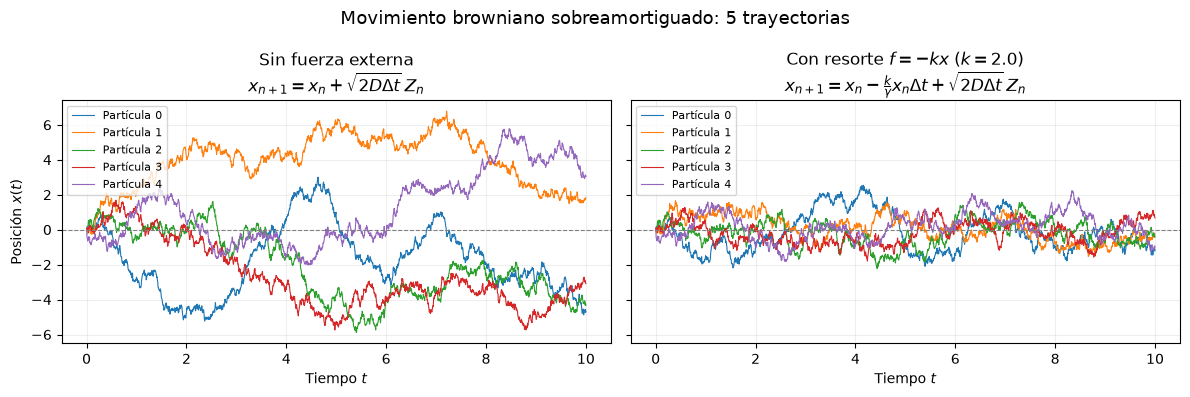

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for i in range(5):                       # solo 5 trayectorias, para que se vea claro
    axes[0].plot(t, x_libre[i],   linewidth=0.8, label=f"Partícula {i}")
    axes[1].plot(t, x_resorte[i], linewidth=0.8, label=f"Partícula {i}")

fig.suptitle("Movimiento browniano sobreamortiguado: 5 trayectorias", fontsize=13)

axes[0].set(
    title="Sin fuerza externa\n" + r"$x_{n+1} = x_n + \sqrt{2D\Delta t}\,Z_n$",
    xlabel="Tiempo $t$", ylabel="Posición $x(t)$"
)
axes[1].set(
    title=f"Con resorte $f=-kx$ ($k={k}$)\n" + r"$x_{n+1} = x_n - \frac{k}{\gamma}x_n\Delta t + \sqrt{2D\Delta t}\,Z_n$",
    xlabel="Tiempo $t$"
)

for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")   # línea de referencia en x = 0
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

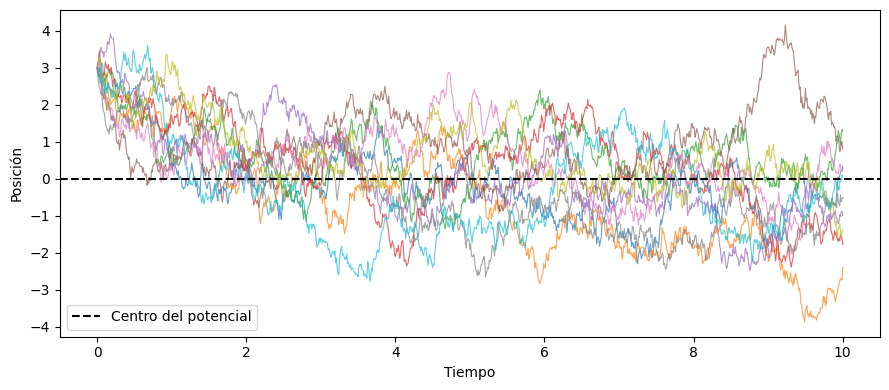

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

# Se define la densidad de probabilidad
def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )
# Se calcula el score asociado a esa distribución
def score(x):
    return -(x - mu) / varianza



**Parámetros: Langevin con score**

Se simulan 200 trayectorias durante 1000 pasos con $\Delta t = 0.01$, es decir, un tiempo total de $t = 10$. Todas las partículas comienzan en $x_0 = 0$ y se mueven según el score:


$$
\mathbf{s}(\mathbf{x})
=
-\mathbf{x}
$$

Se trabaja en unidades donde $D = 1$, por lo que la actualización es

$$
x_{n+1} = x_n + s(x_n)\,\Delta t + \sqrt{2\,\Delta t}\;Z_n, \qquad Z_n \sim \mathcal{N}(0,1).
$$

In [22]:
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x = np.zeros((n_trayectorias, n_pasos +1))
np.shape(x)
t = np.arange(n_pasos+1 ) * dt

In [23]:
# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

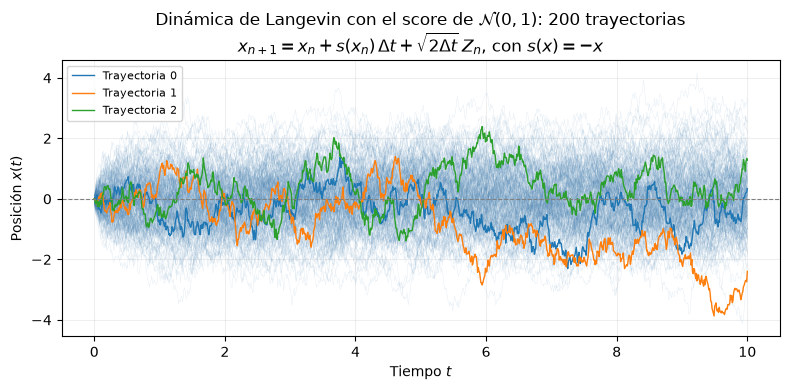

In [27]:
plt.figure(figsize=(8, 4))

# Las 200 trayectorias, delgadas y transparentes
plt.plot(t, x.T, color="steelblue", linewidth=0.3, alpha=0.15)

# Resaltar 3 trayectorias para seguir alguna individualmente
for i in range(3):
    plt.plot(t, x[i], linewidth=1.0, label=f"Trayectoria {i}")

plt.axhline(0, color="gray", linewidth=0.8, linestyle="--")

plt.title("Dinámica de Langevin con el score de $\\mathcal{N}(0,1)$: 200 trayectorias\n"
          r"$x_{n+1} = x_n + s(x_n)\,\Delta t + \sqrt{2\Delta t}\,Z_n$, con $s(x) = -x$")
plt.xlabel("Tiempo $t$")
plt.ylabel("Posición $x(t)$")
plt.legend(fontsize=8, loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Verificación: ¿las muestras siguen la gaussiana objetivo?

Se juntan las posiciones de todas las trayectorias en un solo vector y se comparan con la distribución objetivo $\mathcal{N}(0,1)$.

### Media y varianza

Se espera que la media sea $\approx 0$ y la varianza $\approx 1$.

Como la simulación usa pasos finitos $\Delta t$, la varianza estacionaria de la actualización discreta es ligeramente mayor:

$$
\sigma^2_{\text{discreta}} = \frac{\sigma^2}{1 - \dfrac{\Delta t}{2\sigma^2}} = \frac{1}{1 - 0.005} \approx 1.005
$$



In [17]:
x=np.concat(x)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


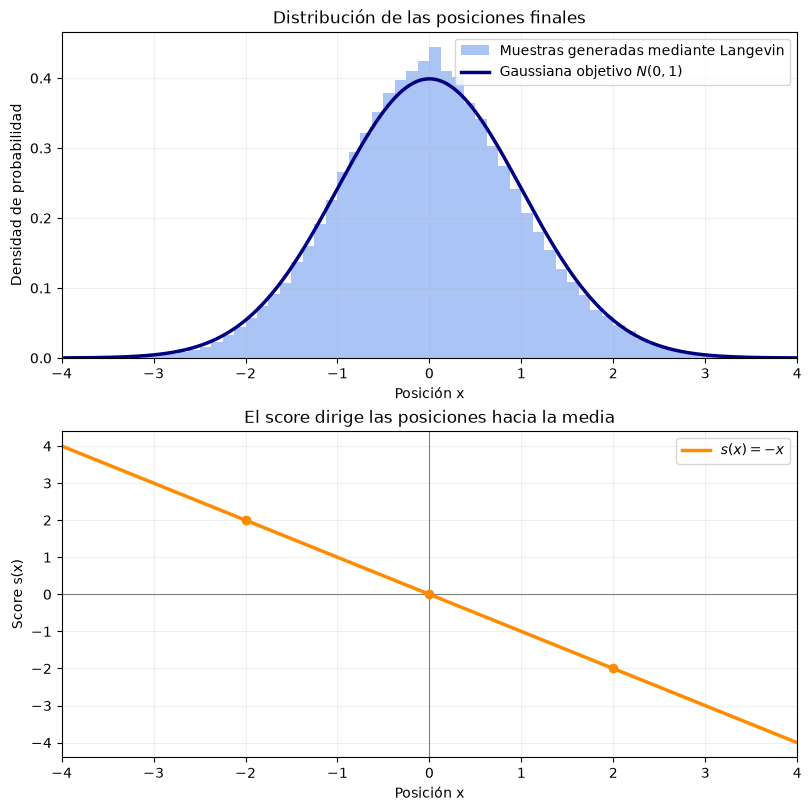

In [18]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

### Análisis de las gráficas

- Se observa el histograma de las muestras generadas con Langevin vs. la densidad gaussiana $p(x)$. Si coinciden, por tanto la dinámica de Langevin generó muestras de $p(x)$ usando solo su score.
- Se muestra también el campo score $s(x) = -x$. Es positivo a la izquierda de la media y negativo a la derecha, así que siempre empuja las partículas hacia $\mu = 0$.

**Nota:** el vector incluye también los primeros pasos, cuando las partículas siguen cerca de $x = 0$, lo que puede subestimar un poco la varianza. Para usar solo el estado final se puede tomar `x[:, -1]`, o descartar los primeros pasos con `x[:, 200:]`.

### Ejercicio

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

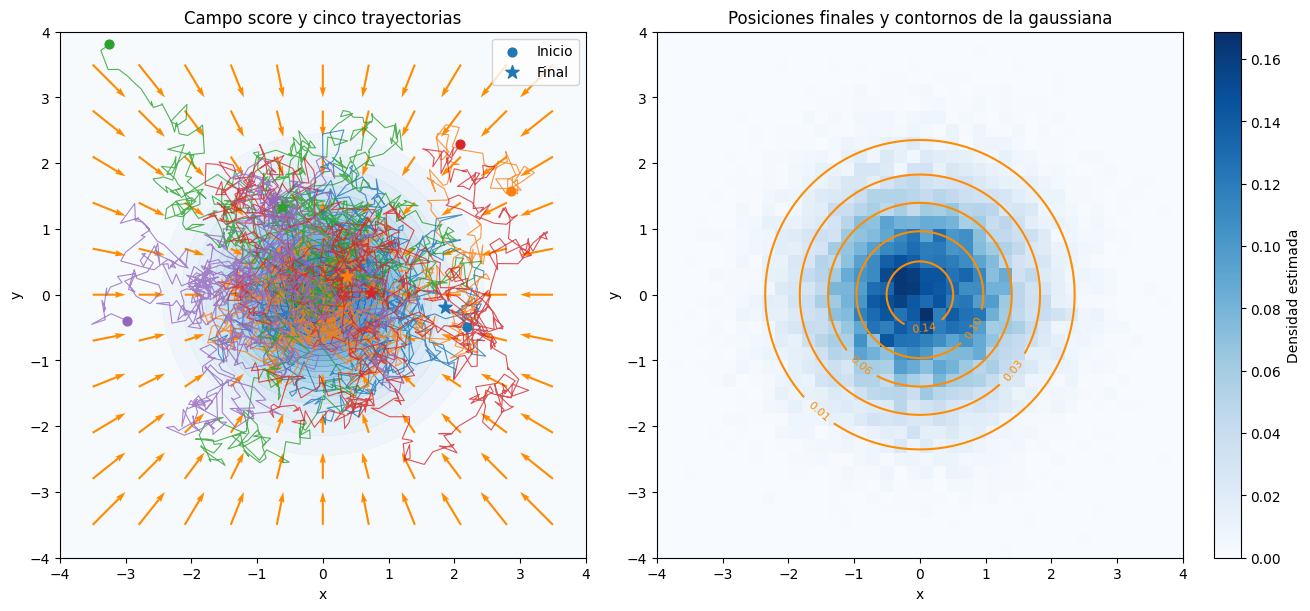

Media final: [ 0.00305783 -0.00499899]
Covarianza final:
[[ 1.01240124e+00 -1.92439710e-04]
 [-1.92439710e-04  1.01758553e+00]]


**Definir los parámetros y función score**

Nota: ver desarrollo matemático en la sección Ejercicio Computacional de las notas en pdf adjuntas a la entrega del laboratorio.

In [ ]:
rng = np.random.default_rng(42)   # generador aleatorio con semilla fija

n_part  = 500     # número de partículas
n_pasos = 1000    # número de pasos de tiempo
dt      = 0.01    # tamaño del paso. Tiempo total = 1000 × 0.01 = 10

mu = np.array([0.0, 0.0])   # centro de la gaussiana objetivo
v  = 1.0                    # varianza en cada dirección 

def score_2d(x):
    """Score de una gaussiana 2D con media mu y covarianza v·I.
    x tiene forma (n_part, 2): una fila por partícula, columnas (x1, x2)."""
    return -(x - mu) / v

Inicializar las posiciones al azar:

In [29]:
# Matriz de posiciones: partículas × tiempos × coordenadas
X = np.zeros((n_part, n_pasos + 1, 2))

# Posiciones iniciales: uniformes en el cuadrado [-4, 4] × [-4, 4]
X[:, 0, :] = rng.uniform(-4, 4, size=(n_part, 2))

In [31]:
for j in range(n_pasos):
    Z = rng.normal(size=(n_part, 2))          # dos números aleatorios N(0,1) por partícula
    X[:, j+1, :] = (X[:, j, :]                            # posición actual
        + score_2d(X[:, j, :]) * dt           # empuje del score
        + np.sqrt(2 * dt) * Z                 # ruido
    )

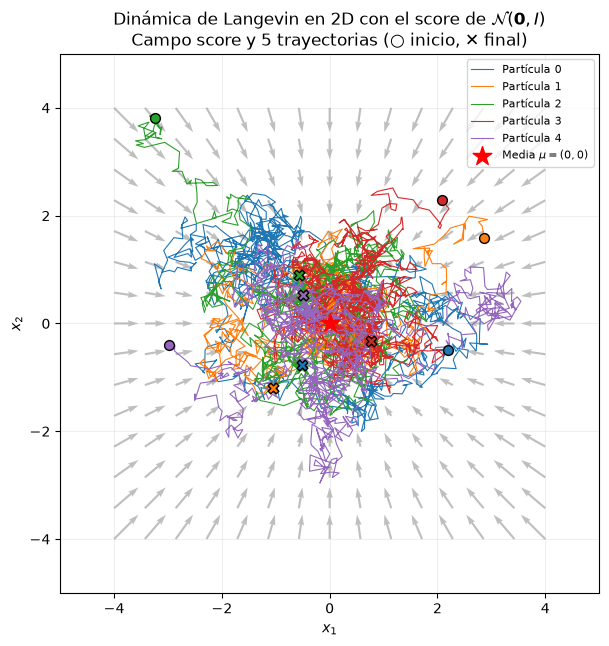

In [ ]:
# Malla de puntos donde se dibujan las flechas
eje = np.linspace(-4, 4, 15)
Q1, Q2 = np.meshgrid(eje, eje)

# Score en cada punto de la malla: s(x) = -(x - mu) / v
U = -(Q1 - mu[0]) / v      # componente x1 de la flecha
V = -(Q2 - mu[1]) / v      # componente x2 de la flecha

fig, ax = plt.subplots(figsize=(7, 7))

# Campo de flechas
ax.quiver(Q1, Q2, U, V, color="gray", alpha=0.5)

# 5 trayectorias
for i in range(5):
    linea, = ax.plot(X[i, :, 0], X[i, :, 1], linewidth=0.8, label=f"Partícula {i}")
    c = linea.get_color()        

    ax.scatter(X[i, 0, 0],  X[i, 0, 1],  color=c, marker="o", s=50, edgecolor="black", zorder=3)  # inicio
    ax.scatter(X[i, -1, 0], X[i, -1, 1], color=c, marker="X", s=60, edgecolor="black", zorder=3)  # final
ax.scatter(*mu, color="red", marker="*", s=200, zorder=4, label=r"Media $\mu = (0,0)$")

ax.set(
    title="Dinámica de Langevin en 2D con el score de $\\mathcal{N}(\\mathbf{0}, I)$\n"
          "Campo score y 5 trayectorias (○ inicio, ✕ final)",
    xlabel="$x_1$", ylabel="$x_2$",
    xlim=(-5, 5), ylim=(-5, 5)
)
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.2)
plt.show()

Media de las muestras: [-0.056  0.012]    (esperado: [0, 0])
Covarianza de las muestras:
 [[1.018 0.046]
 [0.046 0.979]]
Covarianza esperada ≈ 1.005 en la diagonal, 0 fuera


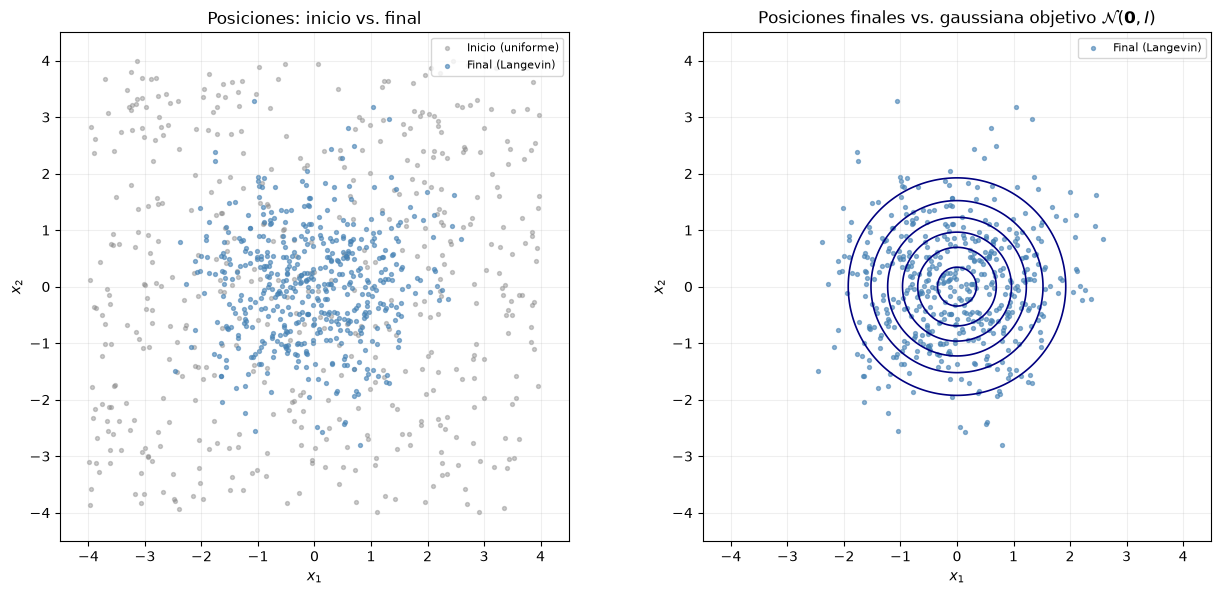

In [ ]:
X_final = X[:, -1, :]          # posiciones finales: forma (500, 2)

# Estadísticas
media = np.mean(X_final, axis=0)    # promedio sobre las partículas (x1, x2)
cov   = np.cov(X_final.T)           # matriz 2×2

print("Media de las muestras:", np.round(media, 3), "   (esperado: [0, 0])")
print("Covarianza de las muestras:\n", np.round(cov, 3))
print("Covarianza esperada ≈", round(v / (1 - dt / (2 * v)), 3), "en la diagonal, 0 fuera")

# Comparación visual 
malla = np.linspace(-4, 4, 200)
G1, G2 = np.meshgrid(malla, malla)
densidad_2d = np.exp(-((G1 - mu[0])**2 + (G2 - mu[1])**2) / (2 * v)) / (2 * np.pi * v)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Gráfico de puntos iniciales comparados con los finales
axes[0].scatter(X[:, 0, 0], X[:, 0, 1], s=8, alpha=0.4, color="gray", label="Inicio (uniforme)")
axes[0].scatter(X_final[:, 0], X_final[:, 1], s=8, alpha=0.6, color="steelblue", label="Final (Langevin)")
axes[0].set(title="Posiciones: inicio vs. final", xlabel="$x_1$", ylabel="$x_2$",
            xlim=(-4.5, 4.5), ylim=(-4.5, 4.5))

# Derecha: posiciones finales sobre las curvas de nivel de la gaussiana objetivo
axes[1].scatter(X_final[:, 0], X_final[:, 1], s=8, alpha=0.6, color="steelblue", label="Final (Langevin)")
axes[1].contour(G1, G2, densidad_2d, levels=6, colors="navy", linewidths=1.2)
axes[1].set(title="Posiciones finales vs. gaussiana objetivo $\\mathcal{N}(\\mathbf{0}, I)$",
            xlabel="$x_1$", ylabel="$x_2$", xlim=(-4.5, 4.5), ylim=(-4.5, 4.5))

for ax in axes:
    ax.set_aspect("equal")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()